# Tests of the BAOAB integrator: lab-scale system

Tests of `src/dynamics.py` (the BAOAB splitting of Sec. 1.4 of `notes/jn_notes.pdf`) for a bar and rails of laboratory size:

| $B_0$ | $T$ | $d$ | $M$ | $l$ | $x_0$ | $v_0$ |
|---|---|---|---|---|---|---|
| 0.1 T | 273 K | 2 mm | 10 g | $100d$ | $500d$ | 10 cm/s |

1. Unit conversion and time scales.
2. The exact O-step preserves the conditional equilibrium $\langle\Phi^2|x\rangle = TL(x)$ for any $h$, Eq. (54).
3. Deterministic limit ($T=0$): second-order convergence to a high-accuracy reference solution of Eq. (46).
4. Energy balance at $T=0$: $H_n-H_0=Q(t_n)+W(t_n)$, with shadow work $W=O(h^2)$, and $Q \simeq -\sum_i Q_{J,i}$, Eqs. (70)-(74).
5. The lab-scale ring-down at $T=273$ K compared with the deterministic one.
6. Thermalization: after the ring-down, $\langle p^2/M\rangle=\langle\Phi^2/L\rangle=T$, the Joule heat rate is $T\langle R/L\rangle$, and the mean heat vanishes.

Every test ends with a `check`; the summary is at the end.

In [1]:
import sys
import numpy as np
import matplotlib.pyplot as plt
from scipy import constants as sc
from scipy.integrate import solve_ivp

sys.path.insert(0, '../src')
from _jit import njit, HAVE_NUMBA
import dynamics as dy

print('numba:', HAVE_NUMBA)

results = []
def check(name, passed, detail=''):
    results.append((name, bool(passed), detail))
    print(f"[{'PASS' if passed else 'FAIL'}] {name}  {detail}")

numba: True


## 1. Units and time scales

Reduced units of Sec. 1.2: $E_0=B_0^2d^3/2\mu_0$, $\tau=\mu_0d^2/\rho_{Cu}$, lengths in $d$, $M^*=Md^2/E_0\tau^2$, $v^*=v\tau/d$, $T^*=k_BT/E_0$. The resistivity of copper is taken at 0 °C, consistent with $T=273$ K.

Back to SI: $L = L^*\mu_0 d/8\pi^2$ and $R = R^*\rho_{Cu}/8\pi^2 d$, Eqs. (36) and (38).

In [2]:
# SI parameters
mu0, kB = sc.mu_0, sc.k
rho_cu = 1.55e-8        # Ohm m, copper at 0 C (1.68e-8 at 20 C)
B0, T_K, d, M_kg = 0.1, 273.0, 2e-3, 10e-3
l_SI, x0_SI, v0_SI = 100 * d, 500 * d, 0.10

# characteristic scales, eqs. (24), (25), (28)
E0 = B0**2 * d**3 / (2 * mu0)
tau = mu0 * d**2 / rho_cu
I0 = 2 * np.pi * B0 * d / mu0

# reduced parameters
l, x0 = l_SI / d, x0_SI / d
M = M_kg * d**2 / (E0 * tau**2)
v0 = v0_SI * tau / d
p0 = M * v0
T = kB * T_K / E0
lam = 4 * np.pi * l

L0, R0 = dy.self_inductance(l, x0), dy.resistance(l, x0)
kappa = R0 / L0                  # relaxation rate of the circuit
omega = lam / np.sqrt(M * L0)    # eq. (26)
tau_b = M * R0 / lam**2          # braking time M R/(B l)^2 of the quasi-static (overdamped) limit
v_th = np.sqrt(T / M)            # thermal velocity of the bar

rows = [
    ('tau', tau, 's'), ('E0', E0, 'J'), ('I0', I0, 'A'),
    ('M*', M, ''), ('v0*', v0, ''), ('T*', T, ''), ('lambda', lam, ''),
    ('L*(x0)', L0, f'= {L0 * mu0 * d / (8 * np.pi**2):.3e} H'),
    ('R*(x0)', R0, f'= {R0 * rho_cu / (8 * np.pi**2 * d):.3e} Ohm'),
    ('kappa = R/L', kappa, f'= 1/({tau / kappa:.3e} s)'),
    ('omega', omega, f'= 1/({tau / omega:.3e} s)'),
    ('gamma/omega', kappa / 2 / omega, '(> 1: overdamped)'),
    ('tau_b = MR/lam^2', tau_b, f'= {tau_b * tau:.3e} s'),
    ('v_th*', v_th, f'= {v_th * d / tau:.3e} m/s'),
    ('v_th/v0', v_th / v0, ''),
]
for name, val, extra in rows:
    print(f'{name:>18s} = {val:.4e} {extra}')

               tau = 3.2429e-04 s
                E0 = 3.1831e-05 J
                I0 = 1.0000e+03 A
                M* = 1.1949e+04 
               v0* = 1.6215e-02 
                T* = 1.1841e-16 
            lambda = 1.2566e+03 
            L*(x0) = 6.9844e+04 = 2.223e-06 H
            R*(x0) = 3.0159e+04 = 2.960e-03 Ohm
       kappa = R/L = 4.3181e-01 = 1/(7.510e-04 s)
             omega = 4.3499e-02 = 1/(7.455e-03 s)
       gamma/omega = 4.9634e+00 (> 1: overdamped)
  tau_b = MR/lam^2 = 2.2821e+02 = 7.401e-02 s
             v_th* = 9.9548e-11 = 6.139e-10 m/s
           v_th/v0 = 6.1394e-09 


The circuit is strongly overdamped ($\gamma\gg\omega$): the bar is braked in a time $\tau_b\approx MR/(B_0l)^2\approx 0.07$ s, moving only a few $d$, so $L$ and $R$ barely change. The thermal velocity is about $10^{-8}$ of $v_0$, so at the lab scale the Johnson noise is invisible in the ring-down; tests 5 and 6 measure it on its own scale.

Helper: a compiled loop that records $(t,x,p,\Phi,Q,Q_J)$, with $Q$ the exact heat of the O-steps, Eq. (70), and $Q_J$ the trapezoidal Joule heat, Eq. (74).

In [3]:
@njit(cache=False)
def run(M, l, x, p, phi, temp, h, nsteps, nrec, seed):
    np.random.seed(seed)
    out = np.empty((nsteps // nrec + 1, 6))  # t, x, p, phi, Q, Q_J
    Q, QJ = 0.0, 0.0
    L, R = dy.self_inductance(l, x), dy.resistance(l, x)
    out[0, 0], out[0, 1], out[0, 2], out[0, 3], out[0, 4], out[0, 5] = 0.0, x, p, phi, 0.0, 0.0
    k = 1
    for i in range(1, nsteps + 1):
        x1, p1, phi1, f0, f1, q = dy.BAOAB_step(M, l, x, p, phi, temp, h)
        L1, R1 = dy.self_inductance(l, x1), dy.resistance(l, x1)
        QJ += 0.5 * h * (R * (phi / L)**2 + R1 * (phi1 / L1)**2)
        Q += q
        x, p, phi, L, R = x1, p1, phi1, L1, R1
        if i % nrec == 0:
            out[k, 0], out[k, 1], out[k, 2], out[k, 3], out[k, 4], out[k, 5] = i * h, x, p, phi, Q, QJ
            k += 1
    return out

def energy(out):
    L = np.array([dy.self_inductance(l, xi) for xi in out[:, 1]])
    return out[:, 2]**2 / (2 * M) + out[:, 3]**2 / (2 * L)

def block_mean(a, nblocks=50):
    # mean and standard error from block averages, for correlated samples
    b = a[: len(a) // nblocks * nblocks].reshape(nblocks, -1).mean(axis=1)
    return b.mean(), b.std(ddof=1) / np.sqrt(nblocks)

## 2. Exact O-step

At frozen $x$, one O-step from $\Phi$ fixed gives a Gaussian with mean $c\Phi$ and variance $TL(1-c^2)$, $c=e^{-hR/L}$; from $\Phi\sim N(0,TL)$ the variance stays $TL$, for any $h$ (Eq. 54). Checked with $10^5$ samples for $\kappa h$ from $10^{-6}$ to $10^2$.

In [4]:
@njit(cache=False)
def o_samples(l, x, phi0, temp, h, n, seed, from_equilibrium):
    np.random.seed(seed)
    L = dy.self_inductance(l, x)
    s = np.empty(n)
    for i in range(n):
        phi = np.sqrt(temp * L) * np.random.normal() if from_equilibrium else phi0
        s[i], _ = dy.ornstein_uhlenbeck_step(l, x, phi, temp, h)
    return s

n = 100_000
ok_mean, ok_var, ok_eq = True, True, True
print(f"{'kappa h':>9s} {'mean/(c Phi0)':>14s} {'var/TL(1-c^2)':>14s} {'var/TL (eq)':>12s}")
for j, kh in enumerate([1e-6, 1e-3, 0.1, 1.0, 10.0, 100.0]):
    h = kh / kappa
    c = np.exp(-kh)
    phi0 = 3 * np.sqrt(T * L0)
    s = o_samples(l, x0, phi0, T, h, n, 2 * j, False)
    var_exp = T * L0 * -np.expm1(-2 * kh)
    r_mean = (s.mean() - c * phi0) / np.sqrt(var_exp / n)   # in standard errors
    r_var = s.var() / var_exp
    r_eq = o_samples(l, x0, 0.0, T, h, n, 2 * j + 1, True).var() / (T * L0)
    ok_mean &= abs(r_mean) < 5
    ok_var &= abs(r_var - 1) < 5 * np.sqrt(2 / n)
    ok_eq &= abs(r_eq - 1) < 5 * np.sqrt(2 / n)
    print(f'{kh:9.0e} {r_mean:+14.2f} {r_var:14.4f} {r_eq:12.4f}')
print('(mean column: deviation from c Phi0 in standard errors)')
check('O-step mean', ok_mean)
check('O-step variance TL(1-c^2)', ok_var, '(tolerance 5 sigma = 2.2%)')
check('O-step preserves <Phi^2|x> = TL', ok_eq)

  kappa h  mean/(c Phi0)  var/TL(1-c^2)  var/TL (eq)
    1e-06          +0.50         0.9947       1.0013
    1e-03          -1.03         1.0041       0.9930
    1e-01          -0.55         0.9942       1.0062
    1e+00          -1.12         0.9953       0.9983
    1e+01          -0.78         0.9996       0.9985
    1e+02          -0.94         0.9988       0.9932
(mean column: deviation from c Phi0 in standard errors)
[PASS] O-step mean  
[PASS] O-step variance TL(1-c^2)  (tolerance 5 sigma = 2.2%)
[PASS] O-step preserves <Phi^2|x> = TL  


## 3. Deterministic limit: convergence to the reference solution

For $T=0$ the scheme is a deterministic second-order integrator of Eq. (46). The reference is `solve_ivp` (DOP853, rtol $10^{-12}$) over $5\tau_b$. The error of $x$ and $p$ should drop by 4 when $h$ is halved.

     h   max|x-x_ref| [d]  ratio  max|p-p_ref|/p0  ratio
  0.80          3.513e-02    nan        3.672e-03    nan
  0.40          8.855e-03   3.97        9.228e-04   3.98
  0.20          2.218e-03   3.99        2.310e-04   3.99
  0.10          5.549e-04   4.00        5.777e-05   4.00
  0.05          1.387e-04   4.00        1.444e-05   4.00
[PASS] second order in x  (fitted order 2.00)
[PASS] second order in p  (fitted order 2.00)


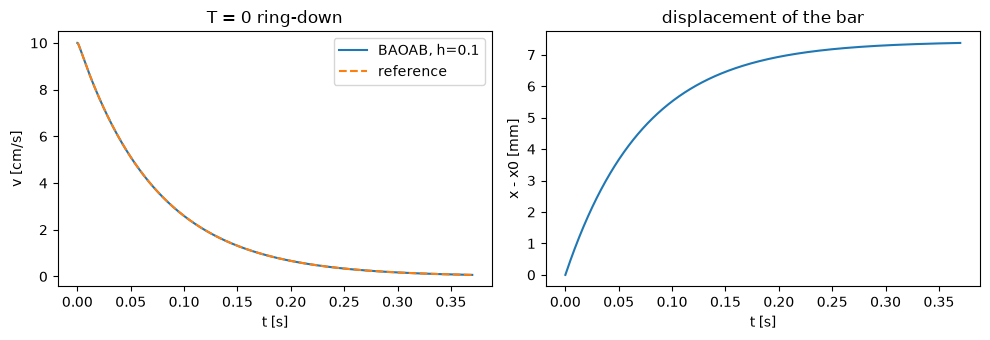

In [5]:
def rhs(t, y):
    x, p, phi = y
    L, Lp, R = dy.self_inductance(l, x), dy.self_inductance_dx(l, x), dy.resistance(l, x)
    return [p / M, Lp * phi**2 / (2 * L**2) - lam * phi / L, lam * p / M - R * phi / L]

hs = [0.8, 0.4, 0.2, 0.1, 0.05]
t_end = round(5 * tau_b / hs[0]) * hs[0]
ref = solve_ivp(rhs, (0, t_end), [x0, p0, 0.0], method='DOP853', rtol=1e-12, atol=1e-14, dense_output=True)

runs0 = {}
err_x, err_p = [], []
for h in hs:
    out = run(M, l, x0, p0, 0.0, 0.0, h, int(round(t_end / h)), 1, 0)
    runs0[h] = out
    y = ref.sol(out[:, 0])
    err_x.append(np.max(np.abs(out[:, 1] - y[0])))
    err_p.append(np.max(np.abs(out[:, 2] - y[1])) / p0)

print(f"{'h':>6s} {'max|x-x_ref| [d]':>18s} {'ratio':>6s} {'max|p-p_ref|/p0':>16s} {'ratio':>6s}")
for i, h in enumerate(hs):
    rx = err_x[i - 1] / err_x[i] if i else np.nan
    rp = err_p[i - 1] / err_p[i] if i else np.nan
    print(f'{h:6.2f} {err_x[i]:18.3e} {rx:6.2f} {err_p[i]:16.3e} {rp:6.2f}')

order_x = np.polyfit(np.log(hs), np.log(err_x), 1)[0]
order_p = np.polyfit(np.log(hs), np.log(err_p), 1)[0]
check('second order in x', abs(order_x - 2) < 0.2, f'(fitted order {order_x:.2f})')
check('second order in p', abs(order_p - 2) < 0.2, f'(fitted order {order_p:.2f})')

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
out = runs0[0.1]
t_s = out[:, 0] * tau
ax[0].plot(t_s, out[:, 2] / M * d / tau * 100, label='BAOAB, h=0.1')
ax[0].plot(t_s, ref.sol(out[:, 0])[1] / M * d / tau * 100, '--', label='reference')
ax[0].set(xlabel='t [s]', ylabel='v [cm/s]', title='T = 0 ring-down')
ax[0].legend()
ax[1].plot(t_s, (out[:, 1] - x0) * d * 1e3)
ax[1].set(xlabel='t [s]', ylabel='x - x0 [mm]', title='displacement of the bar')
plt.tight_layout()

## 4. Energy balance at $T=0$

The heat $Q$ of the O-steps and the shadow work $W=H_n-H_0-Q$ (Eq. 72): $W$ should be $O(h^2)$, and $Q$ should match minus the trapezoidal Joule heat (Eq. 74) up to $O(h^2)$. At the end almost all of the initial kinetic energy $\frac12Mv_0^2$ has gone to the bath.

In [6]:
H0 = p0**2 / (2 * M)
W_max, dQ_max = [], []
for h in hs:
    out = runs0[h]
    W = energy(out) - H0 - out[:, 4]
    W_max.append(np.max(np.abs(W)) / H0)
    dQ_max.append(np.max(np.abs(out[:, 4] + out[:, 5])) / H0)

print(f"{'h':>6s} {'max|W|/H0':>11s} {'max|Q+Q_J|/H0':>14s}")
for h, w, q in zip(hs, W_max, dQ_max):
    print(f'{h:6.2f} {w:11.3e} {q:14.3e}')

order_W = np.polyfit(np.log(hs), np.log(W_max), 1)[0]
order_Q = np.polyfit(np.log(hs), np.log(dQ_max), 1)[0]
check('shadow work O(h^2)', abs(order_W - 2) < 0.2, f'(fitted order {order_W:.2f})')
check('Q = -Q_J up to O(h^2)', abs(order_Q - 2) < 0.2, f'(fitted order {order_Q:.2f})')

out = runs0[0.05]
frac = -out[-1, 4] / H0
print(f'heat released after 5 tau_b: {frac:.5f} of H0 = {-out[-1, 4] * E0 * 1e6:.3f} uJ '
      f'(1/2 M v0^2 = {0.5 * M_kg * v0_SI**2 * 1e6:.3f} uJ)')
check('kinetic energy dissipated', abs(frac - (1 - energy(out)[-1] / H0)) < 1e-4)

     h   max|W|/H0  max|Q+Q_J|/H0
  0.80   2.942e-06      1.023e-02
  0.40   7.251e-07      2.560e-03
  0.20   1.806e-07      6.402e-04
  0.10   4.511e-08      1.601e-04
  0.05   1.128e-08      4.002e-05
[PASS] shadow work O(h^2)  (fitted order 2.01)
[PASS] Q = -Q_J up to O(h^2)  (fitted order 2.00)
heat released after 5 tau_b: 0.99996 of H0 = 49.998 uJ (1/2 M v0^2 = 50.000 uJ)
[PASS] kinetic energy dissipated  


## 5. Lab-scale ring-down at $T=273$ K

Same initial state and $h$, with the Johnson noise on. The difference from the deterministic run should be of the order of the thermal velocity $\sqrt{T/M}$, about $10^{-8}$ of $v_0$.

max |v_T - v_0| / v0 = 1.36e-08
rms (v_T - v_0) after 3 tau_b = 0.94 v_th = 5.80e-10 m/s
[PASS] noise is invisible at lab scale  
[PASS] velocity noise of thermal size  (rms/v_th = 0.94)


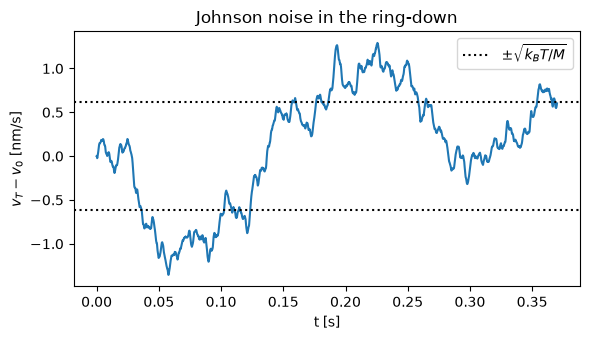

In [7]:
h = 0.1
out0 = runs0[h]
outT = run(M, l, x0, p0, 0.0, T, h, int(round(t_end / h)), 1, 42)
dv = (outT[:, 2] - out0[:, 2]) / M
rms = np.sqrt(np.mean(dv[out0[:, 0] > 3 * tau_b]**2))
print(f'max |v_T - v_0| / v0 = {np.max(np.abs(dv)) / v0:.2e}')
print(f'rms (v_T - v_0) after 3 tau_b = {rms / v_th:.2f} v_th = {rms * d / tau:.2e} m/s')
check('noise is invisible at lab scale', np.max(np.abs(dv)) / v0 < 1e-6)
# a single trajectory over 2 tau_b: only the order of magnitude is meaningful, test 6 is the precise check
check('velocity noise of thermal size', 0.3 < rms / v_th < 3, f'(rms/v_th = {rms / v_th:.2f})')

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(out0[:, 0] * tau, dv * d / tau * 1e9)
ax.axhline(v_th * d / tau * 1e9, ls=':', c='k')
ax.axhline(-v_th * d / tau * 1e9, ls=':', c='k', label=r'$\pm\sqrt{k_BT/M}$')
ax.set(xlabel='t [s]', ylabel=r'$v_T - v_0$ [nm/s]', title='Johnson noise in the ring-down')
ax.legend()
plt.tight_layout()

## 6. Thermalization and heat rates

A long run at $T=273$ K. After discarding $40\tau_b$ (enough for $v_0e^{-t/\tau_b}\ll v_{th}$), the bar and the field should be in equilibrium at fixed $x$ (the bar diffuses by much less than $d$):

* equipartition $\langle p^2/M\rangle=\langle\Phi^2/L\rangle=T$,
* Joule heat rate $\langle RI^2\rangle=T\langle R/L\rangle$, Eq. (69),
* mean heat absorbed $\langle Q\rangle/t\to 0$, small compared with the Joule rate (it is the mean shadow work, $O(h^2)$).

Errors are standard errors from 50 block averages.

x drift during the run: 4.75e-06 d
<p^2/M>/T   = 0.9903 +- 0.0171
<Phi^2/L>/T = 0.9972 +- 0.0023
[PASS] equipartition of the bar  (0.990 +- 0.017)
[PASS] equipartition of the field  (0.997 +- 0.002)
Joule rate, eq. (74) / T<R/L> = 0.9967
<R I^2> / T<R/L>             = 0.9972 +- 0.0023
heat rate <Q>/t / T<R/L>     = +9.87e-07
[PASS] Joule heat rate T<R/L>  (eq. (74): 0.997, <RI^2>: 0.997 +- 0.002)
[PASS] mean heat vanishes  (|<Q>/t| / T<R/L> = 9.9e-07)


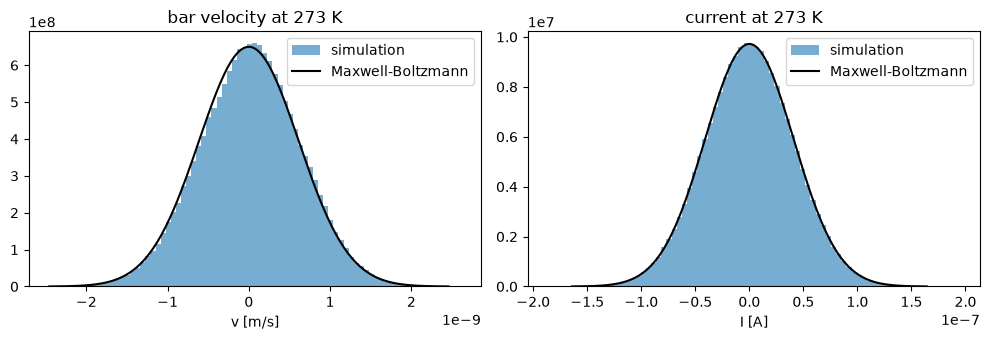

In [8]:
h = 0.2
t_burn = 40 * tau_b
t_run = 4000 * tau_b
nrec = 5
# burn-in and production are separate runs: the accumulators Q, Q_J of the production run must start at 0,
# since the thermal increments (~T h R/L ~ 1e-17) are lost to round-off when added to the ring-down heat (~H0 ~ 1)
burn = run(M, l, x0, p0, 0.0, T, h, int(round(t_burn / h)), int(round(t_burn / h)), 7)
out = run(M, l, burn[-1, 1], burn[-1, 2], burn[-1, 3], T, h, int(round(t_run / h)), nrec, 8)
L = np.array([dy.self_inductance(l, xi) for xi in out[:, 1]])
R = np.array([dy.resistance(l, xi) for xi in out[:, 1]])

kin, kin_err = block_mean(out[:, 2]**2 / M / T)
fld, fld_err = block_mean(out[:, 3]**2 / L / T)
print(f'x drift during the run: {np.ptp(out[:, 1]):.2e} d')
print(f'<p^2/M>/T   = {kin:.4f} +- {kin_err:.4f}')
print(f'<Phi^2/L>/T = {fld:.4f} +- {fld_err:.4f}')
check('equipartition of the bar', abs(kin - 1) < 4 * kin_err, f'({kin:.3f} +- {kin_err:.3f})')
check('equipartition of the field', abs(fld - 1) < 4 * fld_err, f'({fld:.3f} +- {fld_err:.3f})')

t_span = out[-1, 0] - out[0, 0]
rate_J = out[-1, 5] / t_span
rate_th = T * np.mean(R / L)
inst_J, inst_J_err = block_mean(R * (out[:, 3] / L)**2 / rate_th)
rate_Q = out[-1, 4] / t_span
print(f'Joule rate, eq. (74) / T<R/L> = {rate_J / rate_th:.4f}')
print(f'<R I^2> / T<R/L>             = {inst_J:.4f} +- {inst_J_err:.4f}')
print(f'heat rate <Q>/t / T<R/L>     = {rate_Q / rate_th:+.2e}')
check('Joule heat rate T<R/L>', abs(rate_J / rate_th - 1) < 4 * inst_J_err and abs(inst_J - 1) < 4 * inst_J_err,
      f'(eq. (74): {rate_J / rate_th:.3f}, <RI^2>: {inst_J:.3f} +- {inst_J_err:.3f})')
check('mean heat vanishes', abs(rate_Q / rate_th) < 0.05, f'(|<Q>/t| / T<R/L> = {abs(rate_Q / rate_th):.1e})')

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
v_SI = out[:, 2] / M * d / tau
I_SI = out[:, 3] / L * I0
for a, data, sig, lab in [(ax[0], v_SI, np.sqrt(kB * T_K / M_kg), 'v [m/s]'),
                          (ax[1], I_SI, np.sqrt(kB * T_K / (np.mean(L) * mu0 * d / (8 * np.pi**2))), 'I [A]')]:
    a.hist(data, bins=80, density=True, alpha=0.6, label='simulation')
    s = np.linspace(-4 * sig, 4 * sig, 200)
    a.plot(s, np.exp(-s**2 / (2 * sig**2)) / np.sqrt(2 * np.pi * sig**2), 'k', label='Maxwell-Boltzmann')
    a.set(xlabel=lab)
    a.legend()
ax[0].set_title('bar velocity at 273 K')
ax[1].set_title('current at 273 K')
plt.tight_layout()

## Summary

In [9]:
n_pass = sum(p for _, p, _ in results)
for name, passed, detail in results:
    print(f"{'PASS' if passed else 'FAIL'}  {name}  {detail}")
print(f'\n{n_pass}/{len(results)} tests passed')

PASS  O-step mean  
PASS  O-step variance TL(1-c^2)  (tolerance 5 sigma = 2.2%)
PASS  O-step preserves <Phi^2|x> = TL  
PASS  second order in x  (fitted order 2.00)
PASS  second order in p  (fitted order 2.00)
PASS  shadow work O(h^2)  (fitted order 2.01)
PASS  Q = -Q_J up to O(h^2)  (fitted order 2.00)
PASS  kinetic energy dissipated  
PASS  noise is invisible at lab scale  
PASS  velocity noise of thermal size  (rms/v_th = 0.94)
PASS  equipartition of the bar  (0.990 +- 0.017)
PASS  equipartition of the field  (0.997 +- 0.002)
PASS  Joule heat rate T<R/L>  (eq. (74): 0.997, <RI^2>: 0.997 +- 0.002)
PASS  mean heat vanishes  (|<Q>/t| / T<R/L> = 9.9e-07)

14/14 tests passed
